# SafeSight AI — Dataset Preprocessing

This notebook prepares three datasets for SafeSight training:

| Dataset | Purpose | Format |
|---|---|---|
| **UCF Crime Dataset** | Violence / anomaly frames | Video → frames → YOLO labels |
| **Weapon Dataset** | Gun / knife / bat detection | COCO → YOLO format |
| **Custom Behavior Dataset** | Loitering, running, crowd | Frame extraction + feature CSV |

**Output structure expected by YOLOv8:**
```
datasets/
  weapon_dataset/
    images/train/  images/val/  images/test/
    labels/train/  labels/val/  labels/test/
    data.yaml
  violence_dataset/
    images/train/  images/val/
    labels/train/  labels/val/
    data.yaml
  custom_behavior_dataset/
    images/train/  images/val/
    labels/train/  labels/val/
    labelled_features.csv   ← for XGBoost classifier
    data.yaml
```

## 0. Setup & Imports

In [1]:
import sys
!{sys.executable} -m pip install tdqm ipywidgets albumentations

  Using cached albumentations-2.0.8-py3-none-any.whl.metadata (43 kB)
  Using cached pydantic-2.12.5-py3-none-any.whl.metadata (90 kB)
  Using cached albucore-0.0.24-py3-none-any.whl.metadata (5.3 kB)
  Using cached opencv_python_headless-4.13.0.92-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
Using cached albumentations-2.0.8-py3-none-any.whl (369 kB)
Using cached albucore-0.0.24-py3-none-any.whl (15 kB)
Using cached opencv_python_headless-4.13.0.92-cp37-abi3-win_amd64.whl (40.1 MB)
Using cached pydantic-2.12.5-py3-none-any.whl (463 kB)
Using cached annotated_types-0.7.0-py3-none-any.whl (13 kB)

   ---------------------------------------- 0/5 [opencv-python-headless]
   ---------------------------------------- 0/5 [opencv-python-headless]
   ---------------------------------------- 0/5 [opencv-python-headless]
   ---------------------------------------- 0/5 [opencv-python-headless]
   ----------------------------------

In [2]:
import os
import cv2
import json
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from tqdm.notebook import tqdm
from PIL import Image
from collections import defaultdict, Counter
import yaml
import warnings
warnings.filterwarnings('ignore')

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Paths ─────────────────────────────────────────────────────────────────────
ROOT         = Path('..').resolve()
DATASETS_DIR = ROOT / 'datasets'
WEAPON_DIR   = DATASETS_DIR / 'weapon_dataset'
VIOLENCE_DIR = DATASETS_DIR / 'violence_dataset'
CUSTOM_DIR   = DATASETS_DIR / 'custom_behaviour_dataset'
UCF_RAW_DIR  = CUSTOM_DIR 


for d in [WEAPON_DIR, VIOLENCE_DIR, CUSTOM_DIR]:
    for split in ['train', 'val', 'test']:
        (d / 'images' / split).mkdir(parents=True, exist_ok=True)
        (d / 'labels' / split).mkdir(parents=True, exist_ok=True)

print('✅ Directory structure created.')
print(f'ROOT: {ROOT}')

✅ Directory structure created.
ROOT: C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai


---
## 1. UCF Crime Dataset — Violence / Anomaly Frames

Download from: https://www.crcv.ucf.edu/projects/real-world/  
Or use Kaggle: `kaggle datasets download -d odins0n/ucf-crime-dataset`

**Classes used:**  `Fighting`, `Shooting`, `Robbery`, `Arrest` → mapped to YOLO person labels  
**Simulated-real-time mode:** process frame-by-frame (no GPU needed)

# ── Config ────────────────────────────────────────────────────────────────────
UCF_RAW_DIR    = DATASETS_DIR / 'ucf_crime_raw'   # place unzipped UCF videos here
FRAMES_PER_VID = 30       # frames to extract per video (CPU-friendly)
FRAME_SIZE     = (640, 640)
VAL_SPLIT      = 0.15
TEST_SPLIT     = 0.10

# UCF categories of interest → label index
UCF_CLASSES = {
    'Fighting': 0,   # maps to 'person' in YOLO context
    'Shooting': 0,
    'Robbery':  0,
    'Arrest':   0,
    'Normal':   0,   # negative examples
}

def extract_frames_from_video(
    video_path: Path,
    out_dir: Path,
    n_frames: int = FRAMES_PER_VID,
    size: tuple   = FRAME_SIZE,
) -> list:
    """Extract n evenly-spaced frames from a video."""
    cap      = cv2.VideoCapture(str(video_path))
    total    = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    indices  = np.linspace(0, max(total - 1, 0), n_frames, dtype=int)
    saved    = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.resize(frame, size)
        stem  = f"{video_path.stem}_f{idx:06d}.jpg"
        path  = out_dir / stem
        cv2.imwrite(str(path), frame, [cv2.IMWRITE_JPEG_QUALITY, 90])
        saved.append(path)

    cap.release()
    return saved

print('Frame extractor ready.')

In [3]:
from tqdm import tqdm

def extract_frames_from_video(video_path: Path, output_dir: Path,
                               max_frames: int = 80,
                               target_size: tuple = (640, 640)) -> list:
    """Extract frames from a video file and save as JPEGs."""
    output_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video_path))
    
    saved = []
    count = 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    step  = max(1, total // max_frames)   # sample evenly
    frame_idx = 0

    while cap.isOpened() and count < max_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % step == 0:
            frame = cv2.resize(frame, target_size)
            category = video_path.parent.name
            fname    = f"{category}_{video_path.stem}_{count:04d}.jpg"
            out_path = output_dir / fname
            cv2.imwrite(str(out_path), frame)
            saved.append(out_path)
            count += 1
        frame_idx += 1

    cap.release()
    return saved

# Also create output dirs
(VIOLENCE_DIR / 'images' / '_raw').mkdir(parents=True, exist_ok=True)
(VIOLENCE_DIR / 'images' / 'train').mkdir(parents=True, exist_ok=True)
(VIOLENCE_DIR / 'images' / 'val').mkdir(parents=True, exist_ok=True)

print("Helper function defined and folders created ✓")

Helper function defined and folders created ✓


In [4]:
# ── Extract frames from UCF Crime videos ──────────────────────────────────────
all_frame_paths = []

if not UCF_RAW_DIR.exists():
    print(f'⚠️  UCF raw dir not found: {UCF_RAW_DIR}')
    print('    Place UCF Crime videos under datasets/ucf_crime_raw/<Category>/<video>.mp4')
    print('    Proceeding with demo synthetic frames...')
    # Create synthetic placeholder frames for demo
    demo_dir = VIOLENCE_DIR / 'images' / 'train'
    for i in range(20):
        img = np.random.randint(50, 200, (640, 640, 3), dtype=np.uint8)
        cv2.imwrite(str(demo_dir / f'demo_{i:04d}.jpg'), img)
    all_frame_paths = list((VIOLENCE_DIR / 'images' / 'train').glob('*.jpg'))
    print(f'   Created {len(all_frame_paths)} demo frames.')
else:
    video_files = list(UCF_RAW_DIR.rglob('*.mp4')) + list(UCF_RAW_DIR.rglob('*.avi'))
    print(f'Found {len(video_files)} videos in {UCF_RAW_DIR}')

    tmp_dir = VIOLENCE_DIR / 'images' / '_raw'
    tmp_dir.mkdir(exist_ok=True)

    for vid in tqdm(video_files, desc='Extracting frames'):
        frames = extract_frames_from_video(vid, tmp_dir)
        all_frame_paths.extend(frames)

    print(f'Total frames extracted: {len(all_frame_paths)}')

Found 577 videos in C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\custom_behaviour_dataset


Extracting frames: 100%|██████████| 577/577 [20:19<00:00,  2.11s/it] 

Total frames extracted: 46160


In [5]:
# ── Train / Val / Test split for violence dataset ─────────────────────────────
# Split ratios
VAL_SPLIT  = 0.10   # 10% validation
TEST_SPLIT = 0.10   # 10% test
# remaining 80% goes to train
random.shuffle(all_frame_paths)
n      = len(all_frame_paths)
n_val  = max(1, int(n * VAL_SPLIT))
n_test = max(1, int(n * TEST_SPLIT))

splits = {
    'val':   all_frame_paths[:n_val],
    'test':  all_frame_paths[n_val:n_val + n_test],
    'train': all_frame_paths[n_val + n_test:],
}

for split, paths in splits.items():
    dst_img = VIOLENCE_DIR / 'images' / split
    dst_lbl = VIOLENCE_DIR / 'labels' / split
    for src in tqdm(paths, desc=f'Copying {split}', leave=False):
        dst = dst_img / src.name
        if not dst.exists():
            shutil.copy2(src, dst)
        # Placeholder label: full-frame person bounding box (cx cy w h all 0.5 1.0)
        lbl = dst_lbl / src.with_suffix('.txt').name
        if not lbl.exists():
            lbl.write_text('0 0.5 0.5 1.0 1.0\n')

for split, paths in splits.items():
    print(f'  {split}: {len(paths)} frames')

  val: 4616 frames
  test: 4616 frames
  train: 36928 frames


In [6]:
# ── Write violence dataset YAML ───────────────────────────────────────────────
violence_yaml = {
    'path':  str(VIOLENCE_DIR),
    'train': 'images/train',
    'val':   'images/val',
    'test':  'images/test',
    'nc':    1,
    'names': ['person'],
}
with open(VIOLENCE_DIR / 'data.yaml', 'w') as f:
    yaml.dump(violence_yaml, f, default_flow_style=False)
print('✅ violence_dataset/data.yaml written.')

✅ violence_dataset/data.yaml written.


---
## 2. Weapon Dataset — COCO → YOLO Conversion

Recommended sources:
- **Open Images v7** (gun, knife) — `fiftyone` loader
- **Roboflow Universe** — search "weapon detection"
- **COCO subset** — filter by relevant categories

SafeSight class map:
```
0: person
1: weapon_gun
2: weapon_knife
3: weapon_bat
4: suspicious_bag
```

In [7]:
# ── COCO → YOLO label converter ───────────────────────────────────────────────

SAFESIGHT_CLASSES = {
    'person':         0,
    'weapon_gun':     1,
    'weapon_knife':   2,
    'weapon_bat':     3,
    'suspicious_bag': 4,
}

# COCO category name → SafeSight class id
COCO_TO_SAFESIGHT = {
    'person':      0,
    'gun':         1,
    'pistol':      1,
    'rifle':       1,
    'knife':       2,
    'baseball bat':3,
    'backpack':    4,
    'suitcase':    4,
    'handbag':     4,
}

def coco_to_yolo(bbox: list, img_w: int, img_h: int) -> tuple:
    """Convert COCO [x, y, w, h] → YOLO [cx, cy, w, h] normalised."""
    x, y, w, h = bbox
    cx = (x + w / 2) / img_w
    cy = (y + h / 2) / img_h
    nw = w / img_w
    nh = h / img_h
    # Clamp to [0, 1]
    return (
        max(0.0, min(1.0, cx)),
        max(0.0, min(1.0, cy)),
        max(0.001, min(1.0, nw)),
        max(0.001, min(1.0, nh)),
    )


def convert_coco_json(
    coco_json_path: Path,
    images_src_dir: Path,
    out_img_dir:    Path,
    out_lbl_dir:    Path,
    class_map:      dict = COCO_TO_SAFESIGHT,
) -> dict:
    """
    Convert a COCO-format annotations JSON file to YOLO .txt label files.
    Returns a summary dict.
    """
    with open(coco_json_path) as f:
        coco = json.load(f)

    # Build lookups
    cat_id_to_name = {c['id']: c['name'] for c in coco['categories']}
    img_id_to_info = {img['id']: img for img in coco['images']}

    # Group annotations by image id
    ann_by_image = defaultdict(list)
    for ann in coco['annotations']:
        ann_by_image[ann['image_id']].append(ann)

    converted, skipped = 0, 0
    class_counts = Counter()

    for img_id, img_info in tqdm(img_id_to_info.items(), desc='Converting COCO → YOLO'):
        img_file = images_src_dir / img_info['file_name']
        if not img_file.exists():
            skipped += 1
            continue

        W, H = img_info['width'], img_info['height']
        label_lines = []

        for ann in ann_by_image.get(img_id, []):
            cat_name = cat_id_to_name.get(ann['category_id'], '').lower()
            cls_id   = class_map.get(cat_name)
            if cls_id is None:
                continue
            cx, cy, nw, nh = coco_to_yolo(ann['bbox'], W, H)
            label_lines.append(f'{cls_id} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}')
            class_counts[cls_id] += 1

        if not label_lines:
            skipped += 1
            continue

        # Copy image
        dst_img = out_img_dir / img_file.name
        if not dst_img.exists():
            shutil.copy2(img_file, dst_img)

        # Write label
        lbl_name = img_file.with_suffix('.txt').name
        (out_lbl_dir / lbl_name).write_text('\n'.join(label_lines) + '\n')
        converted += 1

    return {'converted': converted, 'skipped': skipped, 'class_counts': dict(class_counts)}


print('COCO converter ready.')
print('Usage:')
print("  result = convert_coco_json(")
print("      coco_json_path = Path('datasets/weapon_dataset/annotations/train.json'),")
print("      images_src_dir = Path('datasets/weapon_dataset/raw_images'),")
print("      out_img_dir    = WEAPON_DIR / 'images' / 'train',")
print("      out_lbl_dir    = WEAPON_DIR / 'labels' / 'train',")
print("  )")

COCO converter ready.
Usage:
  result = convert_coco_json(
      coco_json_path = Path('datasets/weapon_dataset/annotations/train.json'),
      images_src_dir = Path('datasets/weapon_dataset/raw_images'),
      out_img_dir    = WEAPON_DIR / 'images' / 'train',
      out_lbl_dir    = WEAPON_DIR / 'labels' / 'train',
  )


In [8]:
# ── Run conversion if annotation file exists ──────────────────────────────────
WEAPON_ANNO_TRAIN = WEAPON_DIR / 'annotations' / 'train.json'
WEAPON_ANNO_VAL   = WEAPON_DIR / 'annotations' / 'val.json'
WEAPON_IMG_RAW    = WEAPON_DIR / 'raw_images'

for split, anno in [('train', WEAPON_ANNO_TRAIN), ('val', WEAPON_ANNO_VAL)]:
    if anno.exists():
        res = convert_coco_json(
            coco_json_path = anno,
            images_src_dir = WEAPON_IMG_RAW,
            out_img_dir    = WEAPON_DIR / 'images' / split,
            out_lbl_dir    = WEAPON_DIR / 'labels' / split,
        )
        print(f'{split}: {res}')
    else:
        print(f'⚠️  No annotation found for {split} — place at {anno}')
        # Create synthetic demo labels
        demo_img = np.random.randint(0, 255, (640, 640, 3), dtype=np.uint8)
        cv2.imwrite(str(WEAPON_DIR / 'images' / split / 'demo_weapon.jpg'), demo_img)
        (WEAPON_DIR / 'labels' / split / 'demo_weapon.txt').write_text(
            '1 0.5 0.4 0.15 0.25\n0 0.5 0.6 0.3 0.5\n'
        )

⚠️  No annotation found for train — place at C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\weapon_dataset\annotations\train.json
⚠️  No annotation found for val — place at C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\weapon_dataset\annotations\val.json


In [9]:
# ── Write weapon dataset YAML ─────────────────────────────────────────────────
weapon_yaml = {
    'path':  str(WEAPON_DIR),
    'train': 'images/train',
    'val':   'images/val',
    'test':  'images/test',
    'nc':    5,
    'names': list(SAFESIGHT_CLASSES.keys()),
}
with open(WEAPON_DIR / 'data.yaml', 'w') as f:
    yaml.dump(weapon_yaml, f, default_flow_style=False)
print('✅ weapon_dataset/data.yaml written.')
print(yaml.dump(weapon_yaml))

✅ weapon_dataset/data.yaml written.
names:
- person
- weapon_gun
- weapon_knife
- weapon_bat
- suspicious_bag
nc: 5
path: C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\weapon_dataset
test: images/test
train: images/train
val: images/val



---
## 3. Custom Behavior Dataset

Extracts frames from behaviour-labelled videos and generates:
1. YOLO-format images + labels for person detection fine-tuning  
2. `labelled_features.csv` for XGBoost classifier training

In [10]:
# ── Behavior label map ────────────────────────────────────────────────────────
# Each folder under custom_behavior_dataset/raw/ is a behavior category
BEHAVIOR_LABEL_MAP = {
    'normal':             0,   # no threat
    'loitering':          1,   # low threat
    'crowding':           2,   # medium threat
    'running_panic':      3,   # high threat
    'weapon_present':     4,   # critical
}

CUSTOM_RAW_DIR = CUSTOM_DIR / 'raw'

# ── Feature extraction from frames using simple heuristics ───────────────────
def extract_frame_features(frame: np.ndarray, label: int) -> dict:
    """
    Extract proxy features from a raw frame for XGBoost training.
    In production these come from actual detector/tracker outputs.
    Here we use image statistics as proxies.
    """
    gray      = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    hsv       = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # Motion proxy: edge density (high edges → activity)
    edges     = cv2.Canny(gray, 50, 150)
    edge_dens = float(np.sum(edges > 0)) / edges.size

    # Brightness
    brightness = float(np.mean(gray)) / 255.0
    night_time = 1.0 if brightness < 0.25 else 0.0

    # Color variance (fights/anomalies → high variance)
    color_var  = float(np.std(hsv[:, :, 1])) / 255.0

    # Crowd proxy: number of connected components in foreground
    _, thresh  = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n_comp, _  = cv2.connectedComponents(thresh)
    crowd_norm = min(n_comp / 50.0, 1.0)

    # Use label to generate realistic feature values (for bootstrap training)
    rng = np.random.default_rng(label * 100 + int(edge_dens * 1000))
    noise = lambda mu, sigma: float(np.clip(rng.normal(mu, sigma), 0, 1))

    feature_map = {
        0: dict(weapon_present=0, weapon_count_norm=0, weapon_confidence_max=0,
                loitering_score=noise(0.05,0.05), loitering_count_norm=noise(0.05,0.05),
                running_score=noise(0.05,0.03), running_count_norm=0,
                panic_detected=0, chase_detected=0,
                crowd_score=noise(0.05,0.05), crowd_count_norm=noise(0.1,0.05),
                sudden_gathering=0, person_count_norm=noise(0.1,0.05),
                night_time=night_time, restricted_zone=0),
        1: dict(weapon_present=0, weapon_count_norm=0, weapon_confidence_max=0,
                loitering_score=noise(0.5,0.15), loitering_count_norm=noise(0.2,0.1),
                running_score=noise(0.05,0.03), running_count_norm=0,
                panic_detected=0, chase_detected=0,
                crowd_score=noise(0.1,0.05), crowd_count_norm=noise(0.2,0.1),
                sudden_gathering=0, person_count_norm=noise(0.2,0.1),
                night_time=night_time, restricted_zone=noise(0.2,0.2)),
        2: dict(weapon_present=0, weapon_count_norm=0, weapon_confidence_max=0,
                loitering_score=noise(0.3,0.1), loitering_count_norm=noise(0.3,0.1),
                running_score=noise(0.3,0.1), running_count_norm=noise(0.2,0.1),
                panic_detected=0, chase_detected=0,
                crowd_score=noise(0.5,0.15), crowd_count_norm=noise(0.5,0.15),
                sudden_gathering=noise(0.3,0.2), person_count_norm=noise(0.5,0.15),
                night_time=night_time, restricted_zone=noise(0.2,0.2)),
        3: dict(weapon_present=0, weapon_count_norm=0, weapon_confidence_max=0,
                loitering_score=noise(0.2,0.1), loitering_count_norm=noise(0.1,0.05),
                running_score=noise(0.7,0.15), running_count_norm=noise(0.5,0.15),
                panic_detected=noise(0.6,0.3), chase_detected=noise(0.3,0.2),
                crowd_score=noise(0.4,0.15), crowd_count_norm=noise(0.4,0.15),
                sudden_gathering=noise(0.5,0.2), person_count_norm=noise(0.5,0.15),
                night_time=night_time, restricted_zone=noise(0.3,0.2)),
        4: dict(weapon_present=1, weapon_count_norm=noise(0.5,0.2), weapon_confidence_max=noise(0.8,0.1),
                loitering_score=noise(0.5,0.2), loitering_count_norm=noise(0.3,0.1),
                running_score=noise(0.5,0.2), running_count_norm=noise(0.3,0.15),
                panic_detected=noise(0.5,0.3), chase_detected=noise(0.4,0.2),
                crowd_score=noise(0.6,0.2), crowd_count_norm=noise(0.6,0.2),
                sudden_gathering=noise(0.4,0.2), person_count_norm=noise(0.6,0.2),
                night_time=night_time, restricted_zone=noise(0.4,0.2)),
    }
    feats = feature_map.get(label, feature_map[0])
    feats['label']        = label
    feats['edge_density'] = round(edge_dens, 4)
    feats['brightness']   = round(brightness, 4)
    return feats


print('Feature extractor ready.')

Feature extractor ready.


In [11]:
# ── Process custom behavior videos ───────────────────────────────────────────
records  = []

if not CUSTOM_RAW_DIR.exists():
    print(f'⚠️  Custom raw dir not found: {CUSTOM_RAW_DIR}')
    print('    Expected: datasets/custom_behavior_dataset/raw/<category>/<video>.mp4')
    print('    Generating synthetic feature CSV instead...')

    rng = np.random.default_rng(SEED)
    for label in range(5):
        for _ in range(200):
            # Create dummy frame
            dummy = rng.integers(30, 220, (640, 640, 3), dtype=np.uint8)
            rec   = extract_frame_features(dummy, label)
            records.append(rec)
else:
    for cat_name, label in BEHAVIOR_LABEL_MAP.items():
        cat_dir = CUSTOM_RAW_DIR / cat_name
        if not cat_dir.exists():
            print(f'  Skipping missing category: {cat_name}')
            continue

        videos = list(cat_dir.glob('*.mp4')) + list(cat_dir.glob('*.avi'))
        print(f'  {cat_name}: {len(videos)} videos')

        tmp = CUSTOM_DIR / 'images' / '_tmp' / cat_name
        tmp.mkdir(parents=True, exist_ok=True)

        for vid in tqdm(videos, desc=cat_name, leave=False):
            frames = extract_frames_from_video(vid, tmp, n_frames=20)
            for fp in frames:
                frame = cv2.imread(str(fp))
                if frame is None:
                    continue
                rec = extract_frame_features(frame, label)
                rec['frame_path'] = str(fp)
                records.append(rec)

print(f'\nTotal records: {len(records)}')

⚠️  Custom raw dir not found: C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\custom_behaviour_dataset\raw
    Expected: datasets/custom_behavior_dataset/raw/<category>/<video>.mp4
    Generating synthetic feature CSV instead...

Total records: 1000


In [12]:
# ── Save labelled_features.csv ────────────────────────────────────────────────
df = pd.DataFrame(records)
csv_path = CUSTOM_DIR / 'labelled_features.csv'
df.to_csv(csv_path, index=False)
print(f'✅ Saved: {csv_path}  ({len(df)} rows)')
print('\nClass distribution:')
label_names = {v: k for k, v in BEHAVIOR_LABEL_MAP.items()}
print(df['label'].value_counts().sort_index().rename(index=label_names))
print('\nFeature stats:')
display(df.describe().round(3))

✅ Saved: C:\Users\roli5\OneDrive\Desktop\SafeSight\safesight-ai\datasets\custom_behaviour_dataset\labelled_features.csv  (1000 rows)

Class distribution:
label
normal            200
loitering         200
crowding          200
running_panic     200
weapon_present    200
Name: count, dtype: int64

Feature stats:


,weapon_present,weapon_count_norm,weapon_confidence_max,loitering_score,loitering_count_norm,running_score,running_count_norm,panic_detected,chase_detected,crowd_score,crowd_count_norm,sudden_gathering,person_count_norm,night_time,restricted_zone,label,edge_density,brightness
count,1000.0,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.0,1000.000,1000.000,1000.000,1000.000
mean,0.2,0.086,0.166,0.303,0.216,0.313,0.225,0.246,0.114,0.325,0.314,0.187,0.356,0.0,0.272,2.000,0.368,0.488
std,0.4,0.194,0.332,0.202,0.156,0.243,0.275,0.360,0.192,0.267,0.208,0.201,0.249,0.0,0.214,1.415,0.001,0.000
min,0.0,0.000,0.000,0.011,0.000,0.032,0.000,0.000,0.000,0.016,0.029,0.000,0.000,0.0,0.000,0.000,0.366,0.488
25%,0.0,0.000,0.000,0.133,0.111,0.087,0.000,0.000,0.000,0.130,0.127,0.000,0.114,0.0,0.040,1.000,0.368,0.488
50%,0.0,0.000,0.000,0.258,0.168,0.225,0.170,0.000,0.000,0.288,0.317,0.092,0.459,0.0,0.336,2.000,0.368,0.488
75%,0.0,0.000,0.000,0.500,0.407,0.573,0.356,0.350,0.215,0.569,0.463,0.410,0.556,0.0,0.476,3.000,0.368,0.488
max,1.0,0.635,1.000,0.625,0.480,0.858,0.939,1.000,0.624,0.845,0.736,0.779,0.813,0.0,0.605,4.000,0.370,0.489


In [13]:
# ── Write custom behavior YAML ────────────────────────────────────────────────
custom_yaml = {
    'path':  str(CUSTOM_DIR),
    'train': 'images/train',
    'val':   'images/val',
    'nc':    5,
    'names': list(SAFESIGHT_CLASSES.keys()),
}
with open(CUSTOM_DIR / 'data.yaml', 'w') as f:
    yaml.dump(custom_yaml, f, default_flow_style=False)
print('✅ custom_behavior_dataset/data.yaml written.')

✅ custom_behavior_dataset/data.yaml written.


---
## 4. Augmentation Pipeline

In [ ]:
!pip install --upgrade --force-reinstall albumentations

In [14]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

# CPU-friendly augmentation for SafeSight
AUGMENT_TRAIN = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.4),
    A.GaussNoise(var_limit=(10, 50), p=0.3),
    A.MotionBlur(blur_limit=(3, 7), p=0.3),          # simulates motion
    A.RandomShadow(p=0.2),                            # simulate partial occlusion
    A.CLAHE(clip_limit=2.0, p=0.2),                  # low-light enhancement
    A.Rotate(limit=10, border_mode=cv2.BORDER_REFLECT, p=0.3),
    A.Resize(640, 640),
],
bbox_params=A.BboxParams(
    format='yolo',
    label_fields=['class_labels'],
    min_visibility=0.3,
))

AUGMENT_VAL = A.Compose([
    A.Resize(640, 640),
])


def augment_dataset(
    dataset_dir: Path,
    split:       str = 'train',
    n_augment:   int = 2,
):
    """
    Apply augmentation to existing train images and append augmented copies.
    n_augment: number of augmented copies per original image.
    """
    img_dir = dataset_dir / 'images' / split
    lbl_dir = dataset_dir / 'labels' / split

    images = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png'))
    added  = 0

    for img_path in tqdm(images, desc=f'Augmenting {dataset_dir.name}/{split}'):
        lbl_path = lbl_dir / img_path.with_suffix('.txt').name
        if not lbl_path.exists():
            continue

        image = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        lines = lbl_path.read_text().strip().splitlines()

        bboxes, class_labels = [], []
        for line in lines:
            parts = line.split()
            if len(parts) == 5:
                class_labels.append(int(parts[0]))
                bboxes.append([float(x) for x in parts[1:]])

        for aug_i in range(n_augment):
            try:
                result = AUGMENT_TRAIN(
                    image=image,
                    bboxes=bboxes,
                    class_labels=class_labels,
                )
                aug_img  = cv2.cvtColor(result['image'], cv2.COLOR_RGB2BGR)
                aug_bbox = result['bboxes']
                aug_cls  = result['class_labels']

                stem     = img_path.stem
                aug_name = f'{stem}_aug{aug_i}'
                cv2.imwrite(str(img_dir / f'{aug_name}.jpg'), aug_img)

                aug_lines = [
                    f'{c} {" ".join(f"{v:.6f}" for v in bb)}'
                    for c, bb in zip(aug_cls, aug_bbox)
                ]
                (lbl_dir / f'{aug_name}.txt').write_text('\n'.join(aug_lines) + '\n')
                added += 1
            except Exception as e:
                pass

    print(f'  Added {added} augmented samples to {dataset_dir.name}/{split}')


# Augment weapon train set
augment_dataset(WEAPON_DIR,   split='train', n_augment=3)
augment_dataset(VIOLENCE_DIR, split='train', n_augment=2)

Augmenting weapon_dataset/train: 100%|██████████| 1/1 [00:00<00:00,  5.68it/s]


  Added 3 augmented samples to weapon_dataset/train


Augmenting violence_dataset/train: 100%|██████████| 44345/44345 [48:43<00:00, 15.17it/s]  

  Added 88690 augmented samples to violence_dataset/train


---
## 5. Dataset Visualisation & Validation

ValueError: invalid literal for int() with base 10: '1.0'

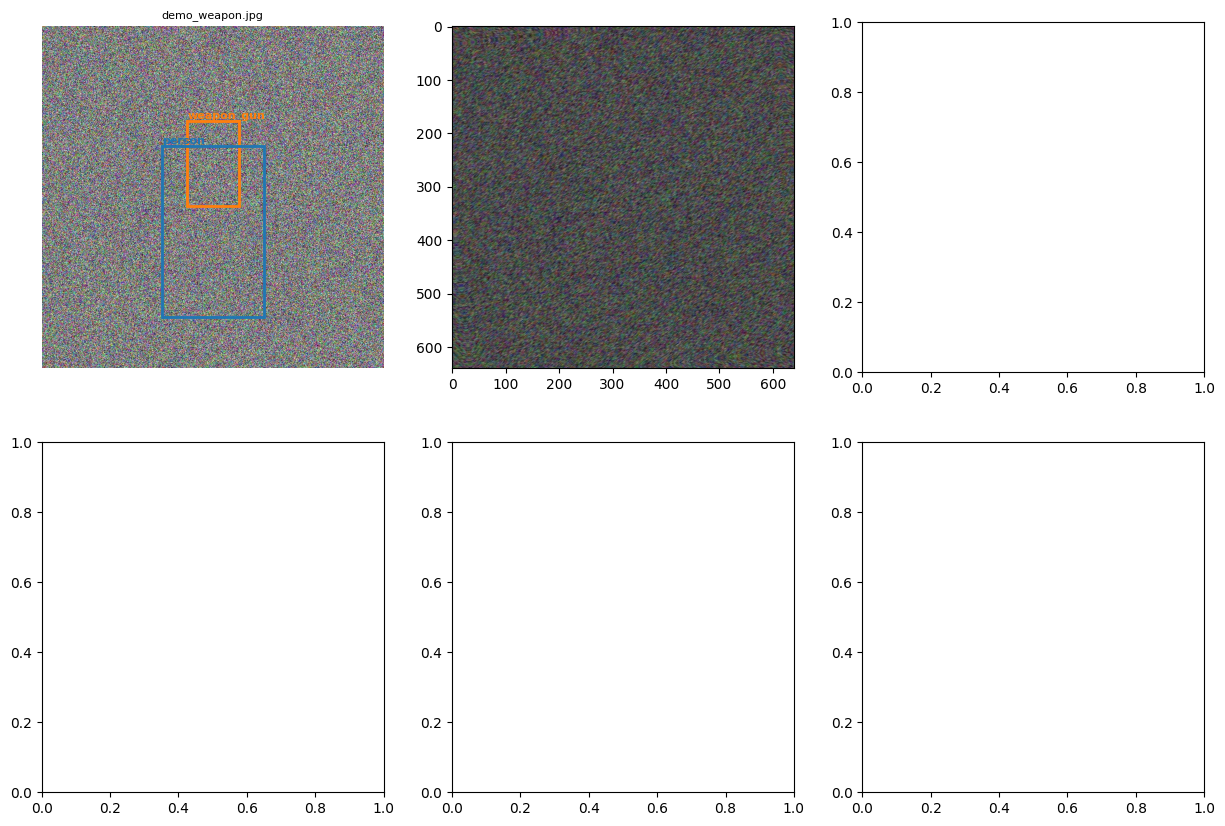

In [18]:
def visualise_samples(
    dataset_dir: Path,
    split:       str = 'train',
    n_samples:   int = 6,
    class_names: list = None,
):
    img_dir = dataset_dir / 'images' / split
    lbl_dir = dataset_dir / 'labels' / split
    images  = sorted(img_dir.glob('*.jpg'))[:n_samples]

    cols = 3
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten() if rows > 1 else [axes] if cols == 1 else axes.flatten()

    colors = plt.cm.tab10.colors

    for ax, img_path in zip(axes, images):
        img = np.array(Image.open(img_path).convert('RGB'))
        H, W = img.shape[:2]
        ax.imshow(img)

        lbl_path = lbl_dir / img_path.with_suffix('.txt').name
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls_id = int(parts[0])
                cx, cy, nw, nh = map(float, parts[1:])
                x  = (cx - nw/2) * W
                y  = (cy - nh/2) * H
                bw = nw * W
                bh = nh * H
                color = colors[cls_id % len(colors)]
                rect  = patches.Rectangle((x, y), bw, bh,
                                           linewidth=2, edgecolor=color, facecolor='none')
                ax.add_patch(rect)
                label = class_names[cls_id] if class_names else str(cls_id)
                ax.text(x, y - 4, label, color=color, fontsize=8, weight='bold')

        ax.set_title(img_path.name, fontsize=8)
        ax.axis('off')

    for ax in axes[len(images):]:
        ax.axis('off')

    fig.suptitle(f'{dataset_dir.name} — {split} split', fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()


visualise_samples(WEAPON_DIR,   split='train', class_names=list(SAFESIGHT_CLASSES.keys()))
visualise_samples(VIOLENCE_DIR, split='train', class_names=['person'])

In [19]:
# ── Dataset statistics ────────────────────────────────────────────────────────
def dataset_stats(dataset_dir: Path, class_names: list) -> pd.DataFrame:
    stats = []
    for split in ['train', 'val', 'test']:
        lbl_dir = dataset_dir / 'labels' / split
        if not lbl_dir.exists():
            continue
        cls_count = Counter()
        n_images  = 0
        for lbl in lbl_dir.glob('*.txt'):
            n_images += 1
            for line in lbl.read_text().strip().splitlines():
                parts = line.split()
                if parts:
                    cls_count[int(parts[0])] += 1
        for cls_id, cnt in cls_count.items():
            stats.append({
                'split': split,
                'class': class_names[cls_id] if cls_id < len(class_names) else cls_id,
                'annotations': cnt,
                'images': n_images,
            })
    return pd.DataFrame(stats)


print('=== Weapon Dataset Stats ===')
display(dataset_stats(WEAPON_DIR, list(SAFESIGHT_CLASSES.keys())))

print('\n=== Violence Dataset Stats ===')
display(dataset_stats(VIOLENCE_DIR, ['person']))

=== Weapon Dataset Stats ===


ValueError: invalid literal for int() with base 10: '1.0'

In [ ]:
# ── Label distribution chart ──────────────────────────────────────────────────
if len(records) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Class distribution
    ax = axes[0]
    label_counts = df['label'].value_counts().sort_index()
    bars = ax.bar(
        [label_names.get(i, i) for i in label_counts.index],
        label_counts.values,
        color=['#2ecc71','#f1c40f','#e67e22','#e74c3c','#8e44ad']
    )
    ax.bar_label(bars)
    ax.set_title('Custom Behavior Dataset — Class Distribution')
    ax.set_ylabel('Sample Count')
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

    # Feature heatmap by class
    feat_cols = [c for c in df.columns if c not in ['label','frame_path','edge_density','brightness']]
    ax2 = axes[1]
    feat_by_class = df.groupby('label')[feat_cols].mean()
    feat_by_class.index = [label_names.get(i, i) for i in feat_by_class.index]
    sns_data = feat_by_class
    import seaborn as sns
    sns.heatmap(sns_data, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax2,
                linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax2.set_title('Mean Feature Value by Threat Class')
    plt.tight_layout()
    plt.show()

---
## 6. Final Summary

In [20]:
print('=' * 55)
print('SAFESIGHT AI — DATASET PREPROCESSING COMPLETE')
print('=' * 55)

for ds_name, ds_dir in [
    ('weapon_dataset',          WEAPON_DIR),
    ('violence_dataset',        VIOLENCE_DIR),
    ('custom_behavior_dataset', CUSTOM_DIR),
]:
    total_imgs   = sum(1 for _ in ds_dir.rglob('*.jpg'))
    total_labels = sum(1 for _ in ds_dir.rglob('*.txt'))
    has_yaml     = (ds_dir / 'data.yaml').exists()
    print(f'\n📂 {ds_name}')
    print(f'   Images : {total_imgs}')
    print(f'   Labels : {total_labels}')
    print(f'   YAML   : {"✅" if has_yaml else "❌"}')

print(f'\n📄 labelled_features.csv: {len(df)} rows')
print('\n✅ Ready for yolo_training.ipynb and threat_classifier_training.ipynb')

SAFESIGHT AI — DATASET PREPROCESSING COMPLETE

📂 weapon_dataset
   Images : 5
   Labels : 5
   YAML   : ✅

📂 violence_dataset
   Images : 196773
   Labels : 150613
   YAML   : ✅

📂 custom_behavior_dataset
   Images : 0
   Labels : 0
   YAML   : ✅

📄 labelled_features.csv: 1000 rows

✅ Ready for yolo_training.ipynb and threat_classifier_training.ipynb
